<a href="https://colab.research.google.com/github/Paosososo/insurance-charges-regression/blob/main/Insurance_Project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ---------------------------------------------------------
# 1. SETUP
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load the dataset directly from a public URL to ensure 100% reproducibility
# This eliminates the need for manual file uploads by the grader.
url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'

try:
    df = pd.read_csv(url)
    print("SUCCESS: 'insurance.csv' loaded correctly from URL!")
    display(df.head())
except Exception as e:
    print(f"ERROR loading dataset: {e}")

SUCCESS: 'insurance.csv' loaded correctly from URL!


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# ---------------------------------------------------------
# 2. DATA UNDERSTANDING
# ---------------------------------------------------------

# Show structural information: column names, non-null counts, and data types
print("--- Dataset Structure & Types ---")
df.info()

# Generate descriptive summary statistics for numerical columns (count, mean, standard deviation, min, max, quartiles)
print("\n--- Summary Statistics ---")
display(df.describe())

--- Dataset Structure & Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

--- Summary Statistics ---


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
# ---------------------------------------------------------
# 3. DATA CLEANING
# ---------------------------------------------------------

# Check for any missing/null values across all columns
print("Missing values per column:\n", df.isnull().sum())

# Handle categorical variables via manual binary encoding
# Convert 'smoker' to 1 (yes) and 0 (no)
df['smoker_encoded'] = df['smoker'].apply(lambda x: 1 if x == 'yes' else 0)

# Convert 'sex' to 1 (male) and 0 (female)
df['sex_encoded'] = df['sex'].apply(lambda x: 1 if x == 'male' else 0)

# Handle multi-class categorical variable 'region' using one-hot encoding (dummy variables)
# drop_first=True prevents perfect multicollinearity (the "dummy variable trap")
# Added a check to see if 'region' column exists before attempting to encode it.
if 'region' in df.columns:
    df = pd.get_dummies(df, columns=['region'], drop_first=True, dtype=int)
else:
    print("Warning: 'region' column not found, skipping one-hot encoding for region.")

print("\n--- Data after Cleaning and Encoding ---")
display(df.head())

Missing values per column:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

--- Data after Cleaning and Encoding ---


,age,sex,bmi,children,smoker,charges,smoker_encoded,sex_encoded,region_northwest,region_southeast,region_southwest
0,19,female,27.900,0,yes,16884.92400,1,0,0,0,1
1,18,male,33.770,1,no,1725.55230,0,1,0,1,0
2,28,male,33.000,3,no,4449.46200,0,1,0,1,0
3,33,male,22.705,0,no,21984.47061,0,1,1,0,0
4,32,male,28.880,0,no,3866.85520,0,1,1,0,0


/tmp/ipykernel_663/895201143.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='smoker', y='charges', data=df, palette='Set2')


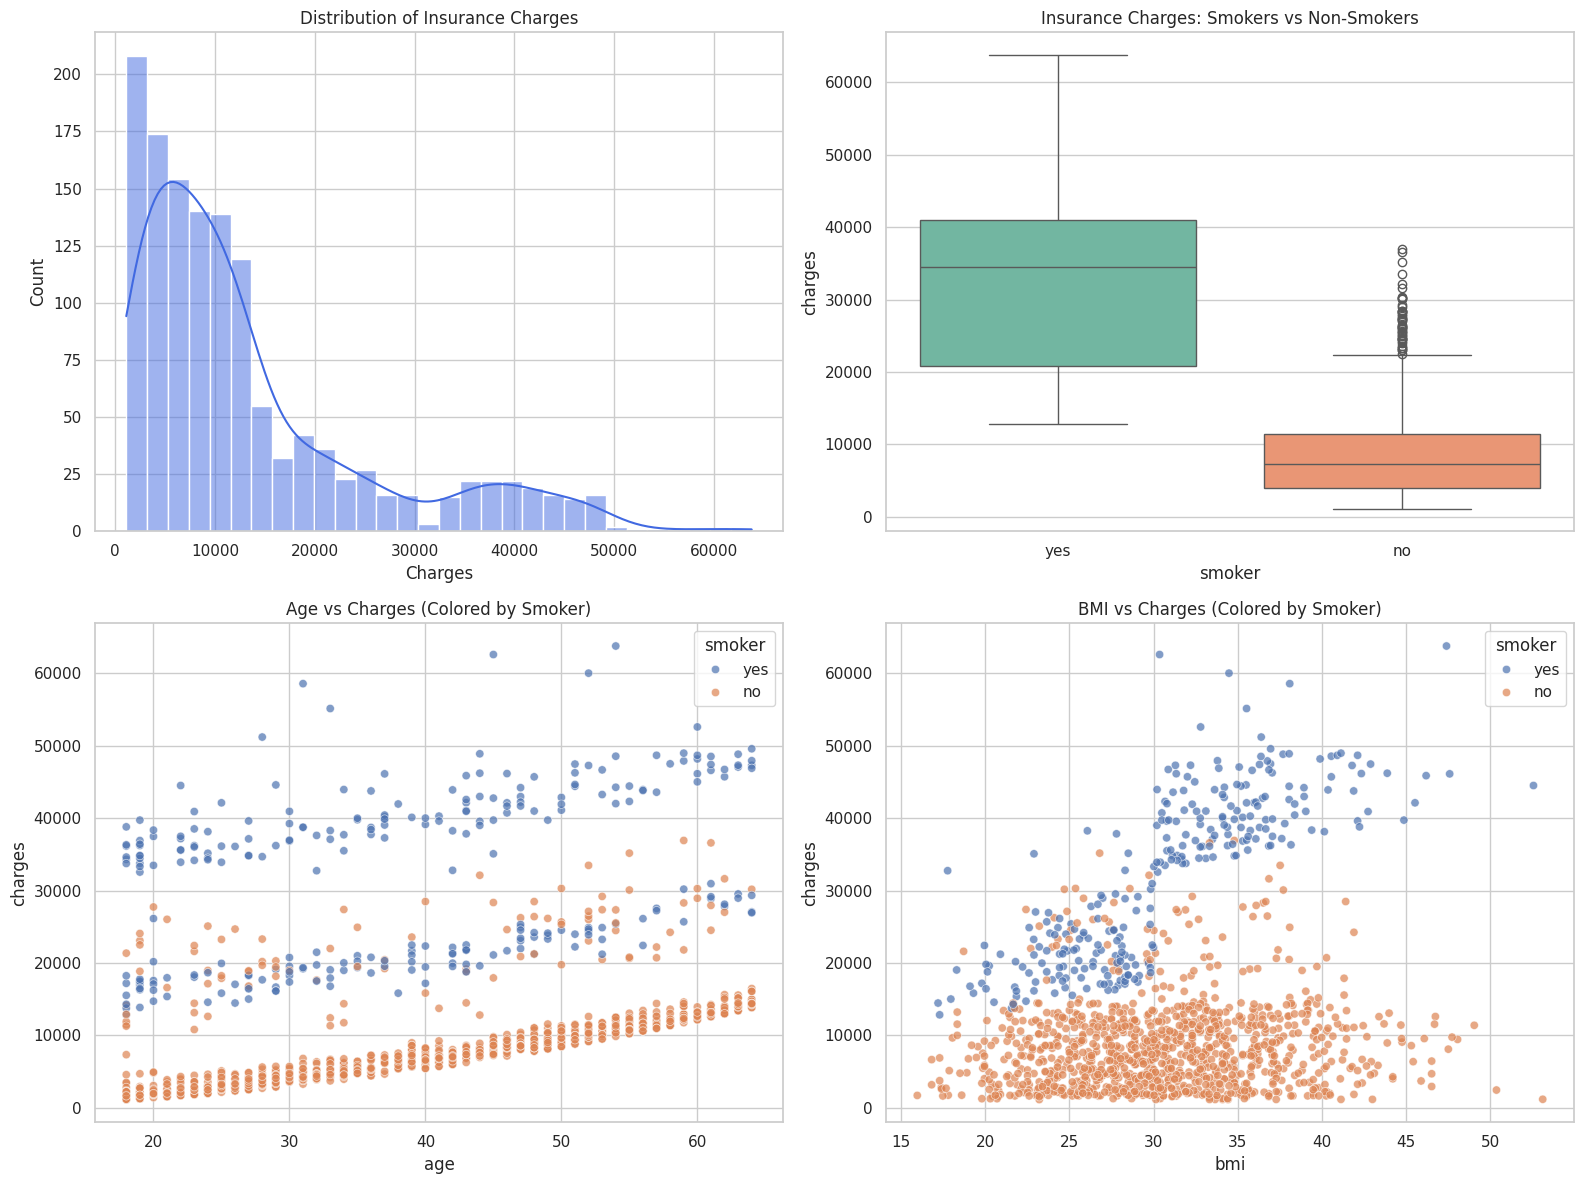

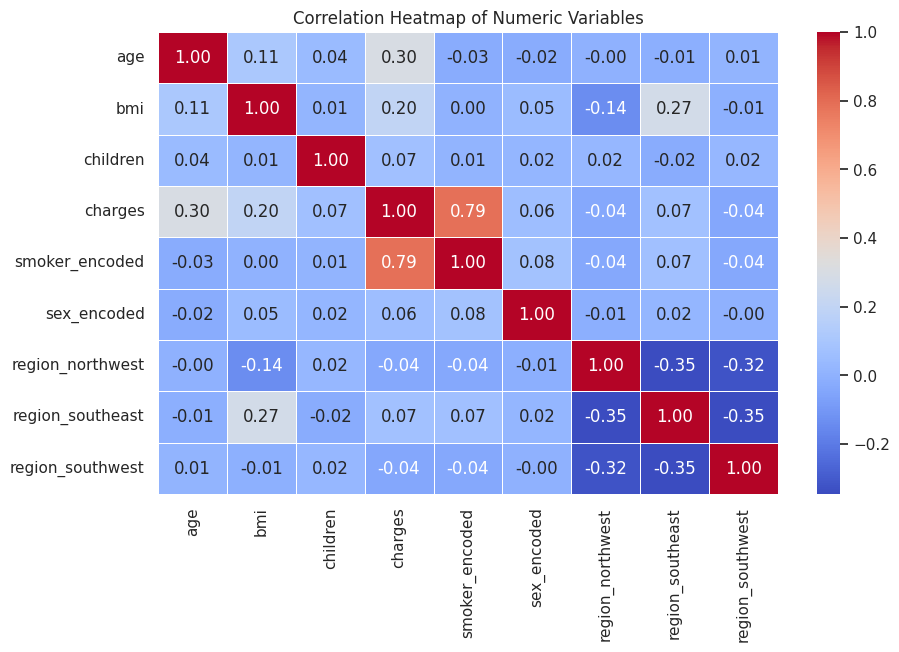

In [ ]:
# ---------------------------------------------------------
# 4. EXPLORATORY DATA ANALYSIS (EDA)
# ---------------------------------------------------------

# Set visual style for plots
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# Plot 1: Histogram to see the distribution of the response variable (charges)
plt.subplot(2, 2, 1)
sns.histplot(df['charges'], kde=True, color='royalblue', bins=30)
plt.title('Distribution of Insurance Charges')
plt.xlabel('Charges')

# Plot 2: Boxplot to compare charge distributions between smokers and non-smokers
plt.subplot(2, 2, 2)
sns.boxplot(x='smoker', y='charges', data=df, palette='Set2')
plt.title('Insurance Charges: Smokers vs Non-Smokers')

# Plot 3: Scatter plot showing relationship between Age and Charges, separated by smoking status
plt.subplot(2, 2, 3)
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, alpha=0.7)
plt.title('Age vs Charges (Colored by Smoker)')

# Plot 4: Scatter plot showing relationship between BMI and Charges, separated by smoking status
plt.subplot(2, 2, 4)
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, alpha=0.7)
plt.title('BMI vs Charges (Colored by Smoker)')

# Display the multi-plot grid
plt.tight_layout()
plt.show()

# Plot 5: Correlation Heatmap to numerically view relationships between all variables
plt.figure(figsize=(10, 6))
# Isolate numeric columns to avoid heatmap errors
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Variables')
plt.show()

In [ ]:
# ---------------------------------------------------------
# 5. INFERENCE (HYPOTHESIS TESTING)
# ---------------------------------------------------------

# Isolate the 'charges' arrays for smokers and non-smokers
charges_smoker = df[df['smoker'] == 'yes']['charges']
charges_nonsmoker = df[df['smoker'] == 'no']['charges']

# Perform an Independent Two-Sample t-test
# equal_var=False (Welch's t-test) is used because the variance of charges between the two groups is likely different
t_stat, p_value = stats.ttest_ind(charges_smoker, charges_nonsmoker, equal_var=False)

# Print Test Statistic and p-value
print("--- Hypothesis Test Results ---")
print(f"Test Statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4e}")

# Interpretation logic based on a standard 0.05 alpha level
if p_value < 0.05:
    print("\nInterpretation: We reject the null hypothesis (H0).")
    print("There is a statistically significant difference in mean insurance charges between smokers and non-smokers.")
else:
    print("\nInterpretation: We fail to reject the null hypothesis (H0).")

--- Hypothesis Test Results ---
Test Statistic: 32.7519
p-value: 5.8895e-103

Interpretation: We reject the null hypothesis (H0).
There is a statistically significant difference in mean insurance charges between smokers and non-smokers.


In [ ]:
# ---------------------------------------------------------
# 5.1 CONFIDENCE INTERVAL COMPUTATION
# ---------------------------------------------------------
import statsmodels.stats.weightstats as ws

# Assuming 'charges_smoker' and 'charges_nonsmoker' were already created in the Hypothesis Test step
# We use statsmodels DescrStatsW to handle the unequal variances (Welch's approach)
smoker_stats = ws.DescrStatsW(charges_smoker)
nonsmoker_stats = ws.DescrStatsW(charges_nonsmoker)

# Compare the means
cm = ws.CompareMeans(smoker_stats, nonsmoker_stats)

# Calculate the 95% confidence interval for the difference (alpha=0.05)
# usevar='unequal' matches the Welch's t-test assumption we used earlier
lower_ci, upper_ci = cm.tconfint_diff(alpha=0.05, usevar='unequal')

# Calculate the exact mean difference
mean_diff = charges_smoker.mean() - charges_nonsmoker.mean()

print("--- Confidence Interval Results ---")
print(f"Mean Difference (Smoker - Non-Smoker): ${mean_diff:,.2f}")
print(f"95% Confidence Interval for the Difference: (${lower_ci:,.2f}, ${upper_ci:,.2f})")

--- Confidence Interval Results ---
Mean Difference (Smoker - Non-Smoker): $23,615.96
95% Confidence Interval for the Difference: ($22,197.21, $25,034.71)


In [ ]:
# ---------------------------------------------------------
# 6. MODELING COMPONENT
# ---------------------------------------------------------

# Model 1: Simple Linear Regression (Y = charges, X1 = age)
# We use Ordinary Least Squares (OLS) from statsmodels
model_1 = smf.ols('charges ~ age', data=df).fit()
print("=== Model 1: Simple Linear Regression ===")
print(model_1.summary())

# Model 2: Multiple Linear Regression (Y = charges, X1=age, X2=bmi, X3=smoker_encoded, X4=children)
model_2 = smf.ols('charges ~ age + bmi + smoker_encoded + children', data=df).fit()
print("\n=== Model 2: Multiple Linear Regression ===")
print(model_2.summary())

=== Model 1: Simple Linear Regression ===
                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.089
Model:                            OLS   Adj. R-squared:                  0.089
Method:                 Least Squares   F-statistic:                     131.2
Date:                Thu, 23 Apr 2026   Prob (F-statistic):           4.89e-29
Time:                        16:04:21   Log-Likelihood:                -14415.
No. Observations:                1338   AIC:                         2.883e+04
Df Residuals:                    1336   BIC:                         2.884e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept 

--- R-squared Comparison ---
Model 1 R-squared: 0.0894 (Explains ~8.9% of variance)
Model 2 Adjusted R-squared: 0.7489 (Explains ~74.9% of variance)


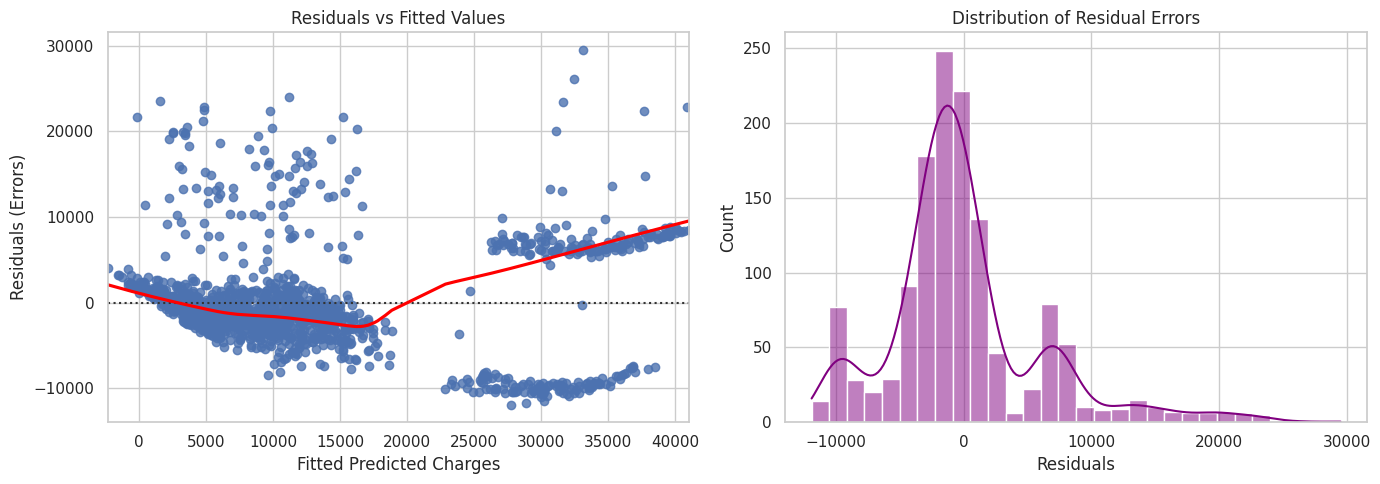

In [ ]:
# ---------------------------------------------------------
# 7. MODEL EVALUATION
# ---------------------------------------------------------

# Compare R-squared metrics
print("--- R-squared Comparison ---")
print(f"Model 1 R-squared: {model_1.rsquared:.4f} (Explains ~8.9% of variance)")
print(f"Model 2 Adjusted R-squared: {model_2.rsquared_adj:.4f} (Explains ~74.9% of variance)")

# Plot Residual Analysis for Model 2
plt.figure(figsize=(14, 5))

# Subplot 1: Residuals vs Fitted values to check for homoscedasticity (constant variance)
plt.subplot(1, 2, 1)
sns.residplot(x=model_2.fittedvalues, y=model_2.resid, lowess=True, line_kws={'color': 'red'})
plt.title('Residuals vs Fitted Values')
plt.xlabel('Fitted Predicted Charges')
plt.ylabel('Residuals (Errors)')

# Subplot 2: Histogram of residuals to check for normality
plt.subplot(1, 2, 2)
sns.histplot(model_2.resid, kde=True, bins=30, color='purple')
plt.title('Distribution of Residual Errors')
plt.xlabel('Residuals')

plt.tight_layout()
plt.show()

In [ ]:
# ---------------------------------------------------------
# 10. ADVANCED MODELING
# ---------------------------------------------------------

# --- Model 3: Adding an Interaction Term ---
# The syntax 'bmi * smoker_encoded' automatically includes bmi, smoker_encoded, and their interaction (bmi:smoker_encoded)
model_3 = smf.ols('charges ~ age + children + bmi * smoker_encoded', data=df).fit()
print("=== Model 3: Multiple Regression with Interaction ===")
print(model_3.summary())

# --- Model 4: Log Transformation of Response Variable ---
# Create a new column for log(charges)
df['log_charges'] = np.log(df['charges'])

# Fit the model predicting log_charges
model_4 = smf.ols('log_charges ~ age + bmi + smoker_encoded + children', data=df).fit()
print("\n=== Model 4: Multiple Regression with Log Transformation ===")
print(model_4.summary())

=== Model 3: Multiple Regression with Interaction ===
                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.839
Model:                            OLS   Adj. R-squared:                  0.838
Method:                 Least Squares   F-statistic:                     1387.
Date:                Thu, 23 Apr 2026   Prob (F-statistic):               0.00
Time:                        16:14:24   Log-Likelihood:                -13256.
No. Observations:                1338   AIC:                         2.652e+04
Df Residuals:                    1332   BIC:                         2.656e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

Model 2 Adjusted R-squared (Baseline): 0.7489
Model 3 Adjusted R-squared (Interaction): 0.8382
Model 4 Adjusted R-squared (Log Transformed): 0.7614 (Note: Different scale)



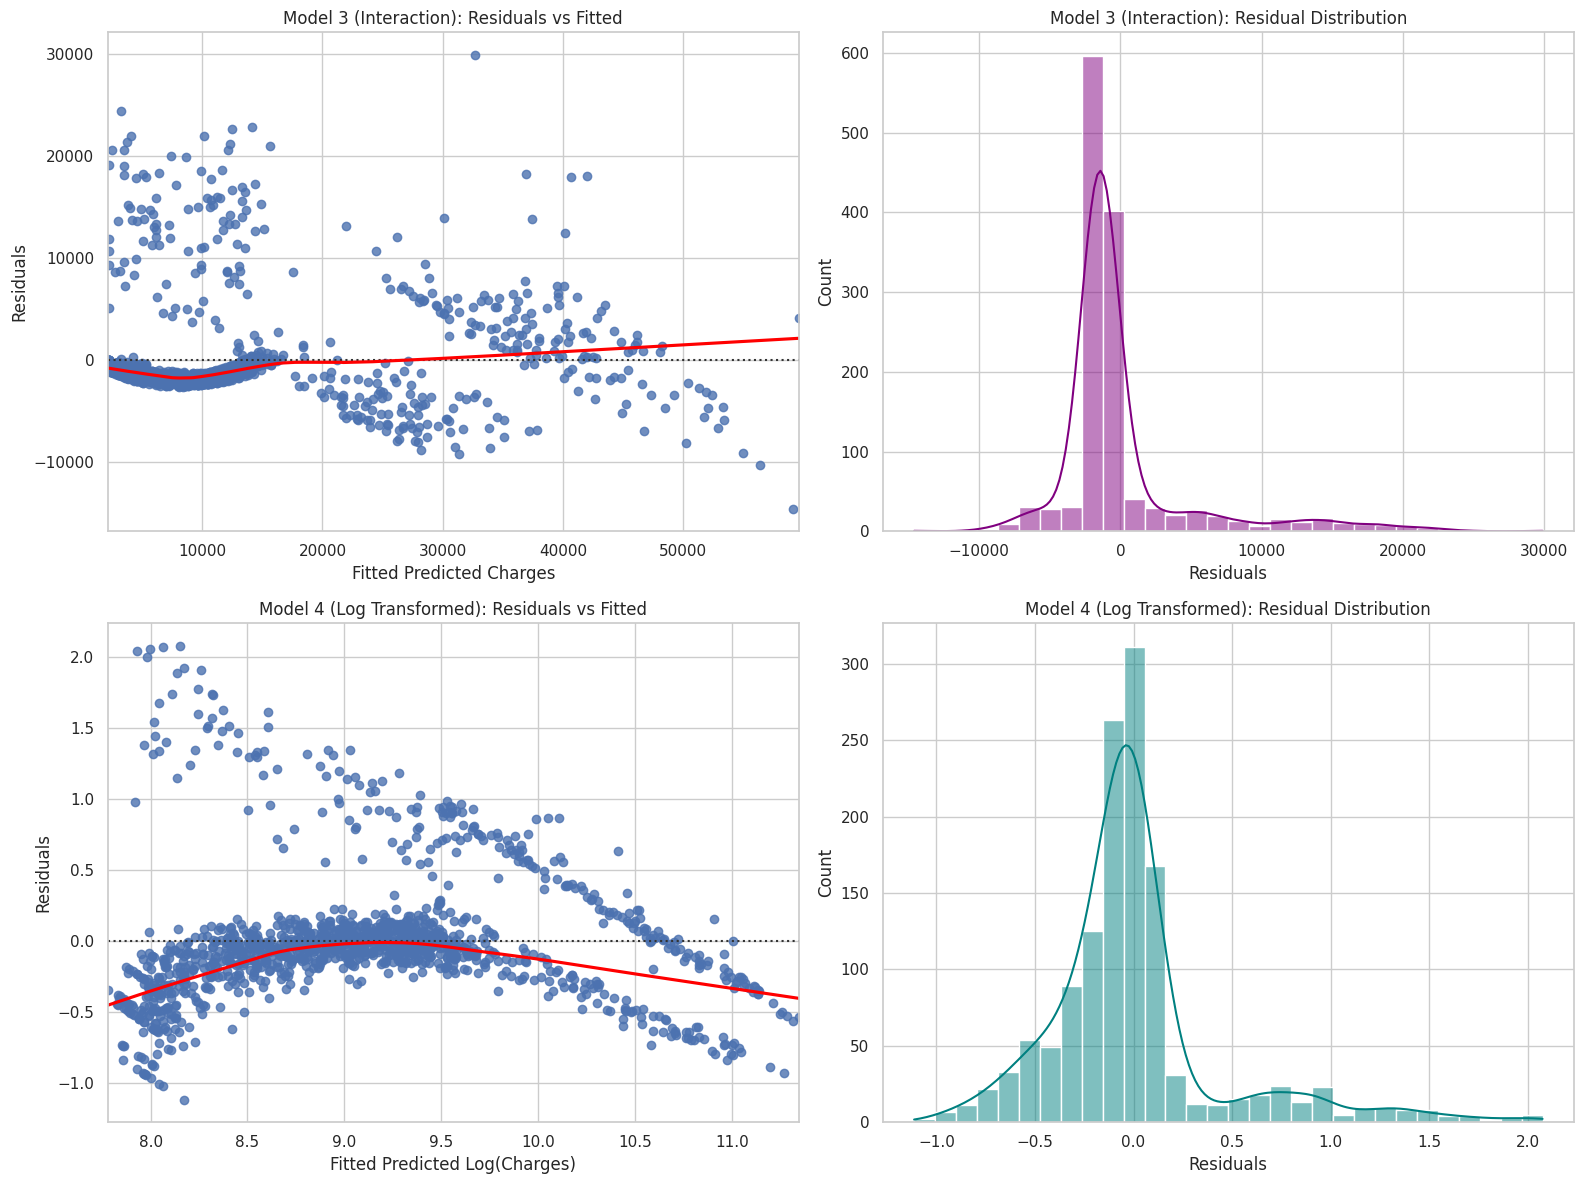

In [ ]:
# ---------------------------------------------------------
# 11. RE-EVALUATING IMPROVED MODELS
# ---------------------------------------------------------

# Extract Adjusted R-squared for Model 3
print(f"Model 2 Adjusted R-squared (Baseline): {model_2.rsquared_adj:.4f}")
print(f"Model 3 Adjusted R-squared (Interaction): {model_3.rsquared_adj:.4f}")
print(f"Model 4 Adjusted R-squared (Log Transformed): {model_4.rsquared_adj:.4f} (Note: Different scale)\n")

# Set up the plot grid
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
sns.set_theme(style="whitegrid")

# --- Plotting Model 3 (Interaction) Residuals ---
# Residuals vs Fitted
sns.residplot(x=model_3.fittedvalues, y=model_3.resid, lowess=True, line_kws={'color': 'red'}, ax=axes[0, 0])
axes[0, 0].set_title('Model 3 (Interaction): Residuals vs Fitted')
axes[0, 0].set_xlabel('Fitted Predicted Charges')
axes[0, 0].set_ylabel('Residuals')

# Histogram of Residuals
sns.histplot(model_3.resid, kde=True, bins=30, color='purple', ax=axes[0, 1])
axes[0, 1].set_title('Model 3 (Interaction): Residual Distribution')
axes[0, 1].set_xlabel('Residuals')

# --- Plotting Model 4 (Log Transformation) Residuals ---
# Residuals vs Fitted
sns.residplot(x=model_4.fittedvalues, y=model_4.resid, lowess=True, line_kws={'color': 'red'}, ax=axes[1, 0])
axes[1, 0].set_title('Model 4 (Log Transformed): Residuals vs Fitted')
axes[1, 0].set_xlabel('Fitted Predicted Log(Charges)')
axes[1, 0].set_ylabel('Residuals')

# Histogram of Residuals
sns.histplot(model_4.resid, kde=True, bins=30, color='teal', ax=axes[1, 1])
axes[1, 1].set_title('Model 4 (Log Transformed): Residual Distribution')
axes[1, 1].set_xlabel('Residuals')

plt.tight_layout()
plt.show()